# 02 — Conformal prediction v1: pixel-level split conformal

The uncertainty layer of the preliminary version of this work (arXiv:2610.13604), recomputed from the cached test logits (CPU only).
The extended paper replaces it with image-level conformal risk control (notebook 03); this notebook shows why.

Model: CBAM + Dice-BCE, TN3K test set (614 images).

Inputs: the logits from the release (or notebook 01, Section 8B) and the ground-truth masks `test_masks.npy`, built from TN3K by notebook 01, Section 8A (CPU).

**Method**
- The 614 test images are split into calibration (30%) and evaluation (70%), stratified by single vs multiple nodules (seed 42).
- Every pixel of every calibration image is a calibration point, with score $s = 1 - \hat p(y)$: $1 - \hat p$ on nodule pixels, $\hat p$ on background pixels.
- $\hat q$ is the conformal quantile of the pooled scores at level $1-\alpha$, with $\alpha = 0.05$.
- Prediction set of a pixel: the labels with score $\le \hat q$. In terms of masks: the inner (lower) mask is $\{\hat p > 1 - \hat q\}$, the outer (upper) mask is $\{\hat p > \hat q\}$, and the band between them is the uncertain region.

**Why it was replaced.** The coverage is computed by pooling pixels across images. About 88% of the pixels are background, mostly easy, so the pooled coverage is inflated and says little about the nodule; and pixels of the same image are dependent, so the guarantee does not hold for individual images.

## 0. Setup and data loading

In [1]:
import os
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.special import expit                      # sigmoid
from scipy.ndimage import label

# Paths: repository root (works from the repo root or from notebooks/), cached logits, outputs
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROJECT_ROOT = Path(os.environ.get("PROJECT_ROOT", REPO_ROOT))
CACHE = Path(os.environ.get("THYROID_CACHE", PROJECT_ROOT / "cache" / "logits"))
FIG_DIR = REPO_ROOT / "figures"
TN3K_IMG = PROJECT_ROOT / "data" / "Thyroid Dataset" / "tn3k" / "test-image"   # only for the figure

MODEL = "CBAM_DiceBCE"
ALPHA = 0.05
SEED = 42

masks = np.load(CACHE / "test_masks.npy").astype(bool)          # (614, 256, 256)
names = (CACHE / "test_names.txt").read_text().splitlines()
probs = expit(np.load(CACHE / f"test_{MODEL}.npy"))              # (614, 256, 256), float32

preds = probs > 0.5
dice_g = 2 * (preds & masks).sum() / (preds.sum() + masks.sum())
print(masks.shape, len(names), f"Dice_g = {100 * dice_g:.2f}")   # expected 89.60 (Table 1)
print(f"Background pixels: {100 * (1 - masks.mean()):.1f}%")     # expected about 88%

(614, 256, 256) 614 Dice_g = 89.60
Background pixels: 87.9%


## 1. Calibration / evaluation split

Number of nodules of each image (connected components of the ground truth), then a split stratified by single vs multiple nodules.
The same function, with the same seed, is used in notebook 03.

In [2]:
n_nod = np.array([label(m)[1] for m in masks])


def stratified_calibration_split(n_nod, calibration_split: float = 0.3, seed: int = 42):
    """Random calibration/test split stratified by single vs multiple nodules.

    Returns:
        (cal_idx, test_idx): sorted lists of image indices
    """
    rng = np.random.default_rng(seed)
    singles   = np.array([i for i in range(len(n_nod)) if n_nod[i] == 1])
    multiples = np.array([i for i in range(len(n_nod)) if n_nod[i] != 1])

    rng.shuffle(singles)
    rng.shuffle(multiples)

    n_cal_single   = round(calibration_split * len(singles))
    n_cal_multiple = round(calibration_split * len(multiples))

    cal_idx  = np.concatenate([singles[:n_cal_single], multiples[:n_cal_multiple]])
    test_idx = np.concatenate([singles[n_cal_single:], multiples[n_cal_multiple:]])
    return sorted(cal_idx), sorted(test_idx)


cal, test = stratified_calibration_split(n_nod, seed=SEED)
print(len(cal), len(test))                                       # expected 184 430

184 430


## 2. Calibration

All calibration pixels are pooled ($184 \times 256 \times 256 \approx 12$ million scores).
With $n$ scores, $\hat q$ is the empirical quantile at level $\lceil (n+1)(1-\alpha) \rceil / n$ (finite-sample correction).

In [3]:
def pixel_scores(p, y):
    """Non-conformity score of every pixel: 1 - p on nodule pixels, p on background pixels."""
    return np.where(y, 1 - p, p)


cal_scores = pixel_scores(probs[cal], masks[cal]).ravel()
n = cal_scores.size
level = math.ceil((n + 1) * (1 - ALPHA)) / n
q_hat = float(np.quantile(cal_scores, min(level, 1.0)))
print(f"n_pixels = {n:,} | q_hat = {q_hat:.4f} | alpha = {ALPHA}")   # expected q_hat = 0.0142

n_pixels = 12,058,624 | q_hat = 0.0142 | alpha = 0.05


## 3. Evaluation

On the 430 evaluation images, overall and for single / multiple nodule images:
- `coverage`: fraction of pixels whose true label is in the prediction set (nodule pixels inside the outer mask, background pixels outside the inner mask), pooled over images;
- `uncertain`: fraction of pixels in the band (outer minus inner mask);
- `upper_dice`, `lower_dice`: Dice of the outer and of the inner mask, from pooled counts.

The last two lines split the coverage between nodule and background pixels: the pooled coverage is dominated by the background.

In [4]:
lower = probs[test] > 1 - q_hat                    # inner mask
upper = probs[test] > q_hat                        # outer mask
y = masks[test]
group = np.where(n_nod[test] == 1, "single", "multiple")


def pooled_metrics(sel):
    """Pooled pixel metrics over the evaluation images selected by the boolean array sel."""
    u, lo, t = upper[sel], lower[sel], y[sel]
    covered = (t & u).sum() + (~t & ~lo).sum()
    dice = lambda m: 2 * (m & t).sum() / (m.sum() + t.sum())
    return {"n_img": int(sel.sum()),
            "coverage": covered / t.size,
            "uncertain": (u & ~lo).sum() / t.size,
            "upper_dice": dice(u),
            "lower_dice": dice(lo)}


results = pd.DataFrame({
    "overall":  pooled_metrics(np.ones(len(test), bool)),
    "single":   pooled_metrics(group == "single"),
    "multiple": pooled_metrics(group == "multiple"),
}).T
print(results.round(4))
# expected overall:  430  0.9874  0.0353  0.8712  0.8731
#          single:   381  0.9888  0.0353  0.8803  0.8817
#          multiple:  49  0.9768  0.0351  0.7813  0.7842

print(f"\ncoverage on nodule pixels:     {(y & upper).sum() / y.sum():.4f}")
print(f"coverage on background pixels: {(~y & ~lower).sum() / (~y).sum():.4f}")

          n_img  coverage  uncertain  upper_dice  lower_dice
overall   430.0    0.9874     0.0353      0.8712      0.8731
single    381.0    0.9888     0.0353      0.8803      0.8817
multiple   49.0    0.9768     0.0351      0.7813      0.7842

coverage on nodule pixels:     0.9409
coverage on background pixels: 0.9936


## 4. Figure

Four evaluation images (the first 16 evaluation images, 4 drawn with seed 62, as in the preliminary version).
Left: image and ground truth (red). Right: inner mask (blue) and uncertainty band (green).
Needs the TN3K test images.

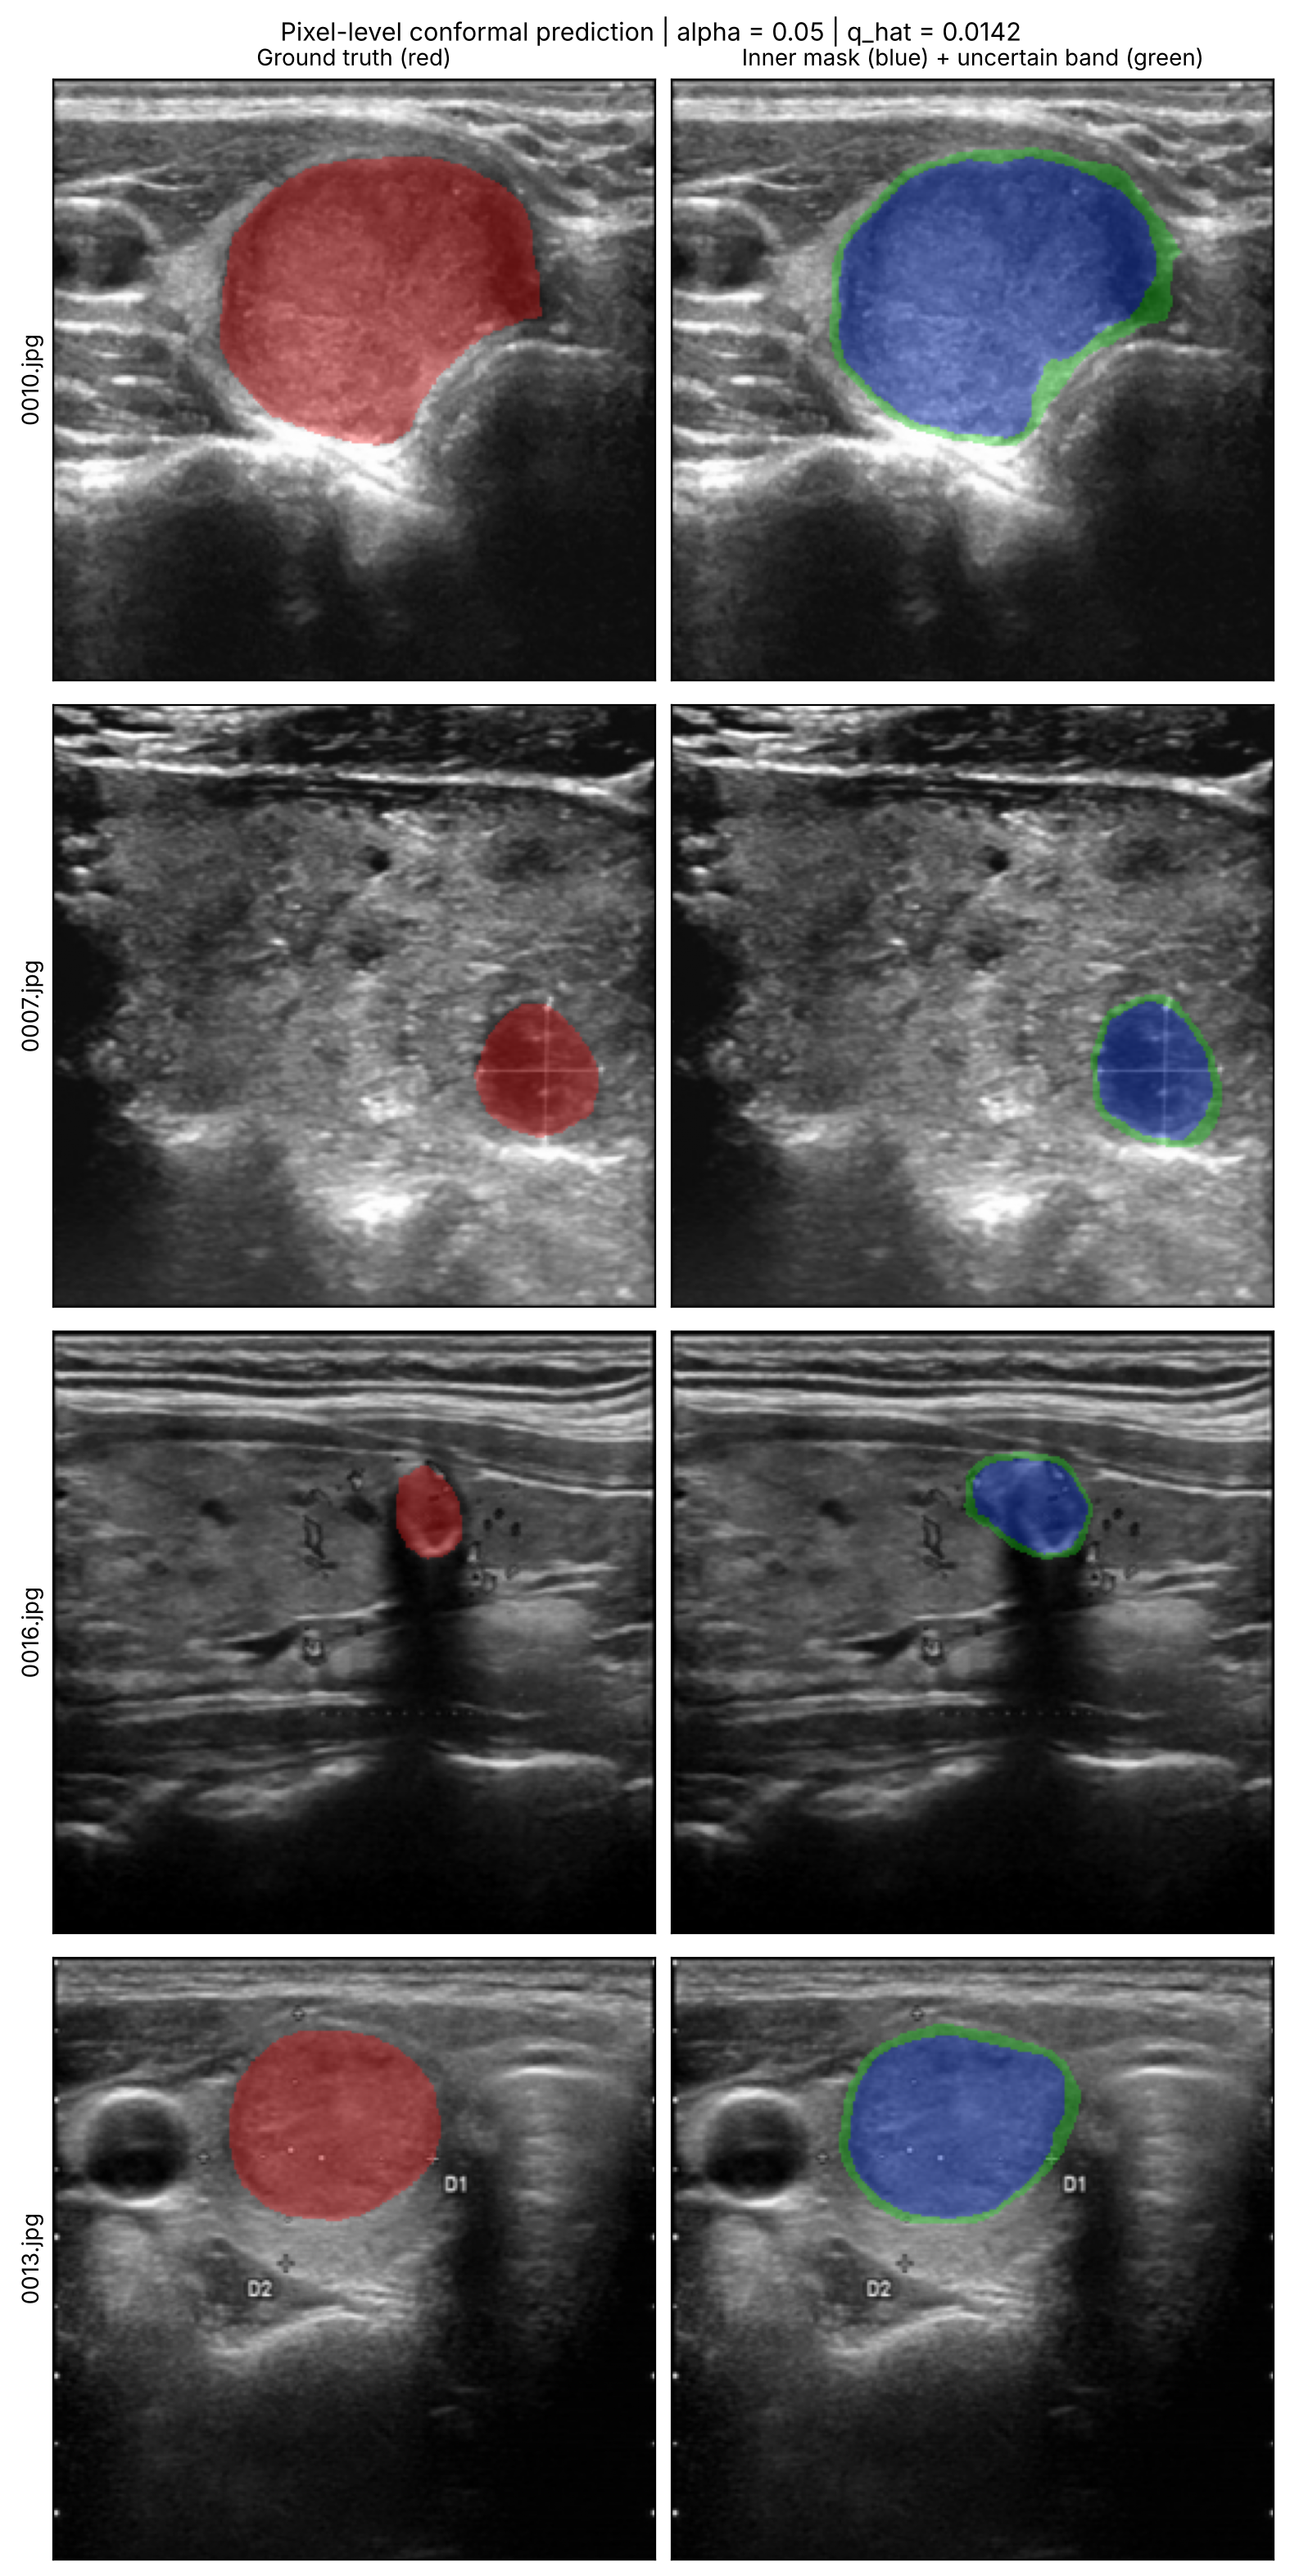

In [5]:
def load_img(i):
    img = Image.open(TN3K_IMG / names[i]).convert("RGB")      # grayscale files become 3 channels, as in training
    return np.asarray(img.resize((256, 256), Image.BILINEAR))


def overlay(img, layers, a=0.35):
    out = img.astype(float) / 255
    for m, color in layers:
        out[m] = (1 - a) * out[m] + a * np.array(color)
    return out


sel = np.random.default_rng(62).choice(16, size=4, replace=False)
cases = [test[k] for k in sel]

fig, axes = plt.subplots(len(cases), 2, figsize=(8, 4 * len(cases)))
for row, i in enumerate(cases):
    img = load_img(i)
    inner = probs[i] > 1 - q_hat
    band = (probs[i] > q_hat) & ~inner
    axes[row, 0].imshow(overlay(img, [(masks[i], (1.0, 0.1, 0.1))]))
    axes[row, 1].imshow(overlay(img, [(inner, (0.1, 0.3, 1.0)), (band, (0.1, 0.9, 0.1))]))
    axes[row, 0].set_ylabel(names[i])
    for ax in axes[row]:
        ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_title("Ground truth (red)", fontsize=10)
axes[0, 1].set_title("Inner mask (blue) + uncertain band (green)", fontsize=10)
plt.suptitle(f"Pixel-level conformal prediction | alpha = {ALPHA} | q_hat = {q_hat:.4f}", fontsize=11)
plt.tight_layout()
FIG_DIR.mkdir(exist_ok=True)
plt.savefig(FIG_DIR / "fig_conformal_v1.png", dpi=200, bbox_inches="tight")
plt.show()